In [1]:
!pip install -q sentence-transformers scikit-learn pandas numpy matplotlib seaborn joblib

In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import OneHotEncoder
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

from sentence_transformers import SentenceTransformer

import joblib

import warnings
warnings.filterwarnings("ignore")

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [3]:
from google.colab import files

uploaded = files.upload()

Saving News_Classification_Dataset.csv to News_Classification_Dataset.csv


In [4]:
# TEP 5 — Inspect the dataset
import os

file_name = list(uploaded.keys())[0]

print("Uploaded file:", file_name)

df = pd.read_csv(file_name)

print("Dataset loaded successfully.")
print("Shape:", df.shape)

df.head()

Uploaded file: News_Classification_Dataset.csv
Dataset loaded successfully.
Shape: (5000, 4)


,URL,Title,Category,Group Leader
0,https://asiatimes.com/2025/10/vietnam-airlines...,Vietnam Airlines data leak exposes a crisis of...,Technology,NaN
1,https://asiatimes.com/2025/10/doj-seizes-15-bi...,DOJ seizes $15 billion bitcoin in SE Asia cryp...,Markets,NaN
2,https://www.fool.com/investing/2025/10/15/too-...,Think It's Too Late to Buy IonQ? Here's the 1 ...,Markets,NaN
3,https://www.fool.com/investing/2025/10/15/inte...,Intel's Crucial Panther Lake Chips Start Produ...,Technology,NaN
4,https://www.fool.com/investing/2025/10/15/3-ro...,3 Robotics Stocks to Buy in October,Markets,NaN


In [5]:
# STEP 6 — Basic cleaning
required_columns = ["URL", "Title", "Category", "Group Leader"]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing columns: {missing_columns}"
    )

print("All required columns are present.")

All required columns are present.


In [6]:
# Keep only useful columns
df = df[["URL", "Title", "Category", "Group Leader"]].copy()

# Remove rows without titles
df = df.dropna(subset=["Title"])

# Remove duplicate titles
df = df.drop_duplicates(subset=["Title"])

# Clean text columns
df["Title"] = df["Title"].astype(str).str.strip()
df["Category"] = df["Category"].astype(str).str.strip()
df["Group Leader"] = df["Group Leader"].astype(str).str.strip()

# Remove empty titles
df = df[df["Title"].str.len() > 5]

# Reset index
df = df.reset_index(drop=True)

print("Cleaned dataset shape:", df.shape)

Cleaned dataset shape: (4578, 4)


EXISTING NEWS CATEGORIES
Category
Business      1724
Markets       1388
Politics       816
Technology     398
Health         134
Energy         117
nan              1
Name: count, dtype: int64


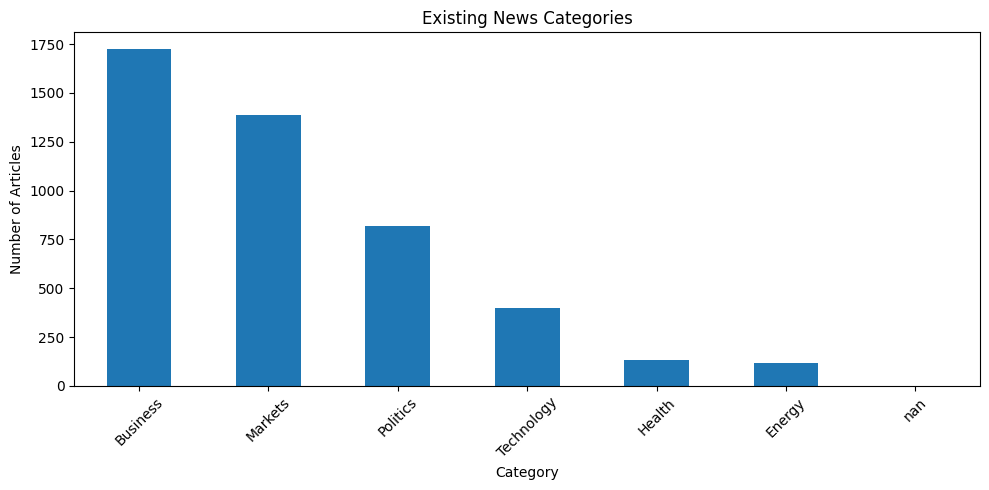

In [7]:
# STEP 7 — Understand your existing categories

print("=" * 70)
print("EXISTING NEWS CATEGORIES")
print("=" * 70)

category_counts = df["Category"].value_counts()

print(category_counts)

plt.figure(figsize=(10, 5))

category_counts.plot(kind="bar")

plt.title("Existing News Categories")
plt.xlabel("Category")
plt.ylabel("Number of Articles")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [8]:
# ================================================================
# STEP 8: FINAL CATEGORY CLEANING
# ================================================================
# Purpose:
#   Remove invalid/missing category values before creating
#   news representations and user preferences.
# ================================================================

print("=" * 70)
print("STEP 8: FINAL CATEGORY CLEANING")
print("=" * 70)

# Convert common text representations of missing values into real NaN
df["Category"] = df["Category"].replace(
    ["nan", "NaN", "None", ""],
    np.nan
)

# Display number of missing categories
print("Missing categories before removal:",
      df["Category"].isna().sum())

# Remove rows where category is missing
df = df.dropna(subset=["Category"]).copy()

# Reset index after removing rows
df = df.reset_index(drop=True)

print("Dataset shape after category cleaning:", df.shape)

print("\nFinal category distribution:")
print(df["Category"].value_counts())

print("\nNumber of categories:",
      df["Category"].nunique())

STEP 8: FINAL CATEGORY CLEANING
Missing categories before removal: 1
Dataset shape after category cleaning: (4577, 4)

Final category distribution:
Category
Business      1724
Markets       1388
Politics       816
Technology     398
Health         134
Energy         117
Name: count, dtype: int64

Number of categories: 6


In [9]:
# ================================================================
# STEP 8: REMOVE UNNECESSARY COLUMNS
# ================================================================
# Purpose:
#   Remove URL and Group Leader because they are not required for
#   our personalized news recommendation task.
#
#   We will keep:
#       1. Title     -> used for semantic embeddings
#       2. Category  -> original news category
# ================================================================

print("=" * 70)
print("STEP 8: REMOVING UNNECESSARY COLUMNS")
print("=" * 70)

# Columns that are not required for our recommendation model
columns_to_drop = [
    "URL",
    "Group Leader"
]

# Drop the columns
df = df.drop(
    columns=columns_to_drop,
    errors="ignore"
)

# Reset index after modifying the dataset
df = df.reset_index(drop=True)

print("Dropped columns:")
print(columns_to_drop)

print("\nRemaining columns:")
print(df.columns.tolist())

print("\nDataset shape:")
print(df.shape)

print("\nFirst 5 rows:")
display(df.head())

STEP 8: REMOVING UNNECESSARY COLUMNS
Dropped columns:
['URL', 'Group Leader']

Remaining columns:
['Title', 'Category']

Dataset shape:
(4577, 2)

First 5 rows:


,Title,Category
0,Vietnam Airlines data leak exposes a crisis of...,Technology
1,DOJ seizes $15 billion bitcoin in SE Asia cryp...,Markets
2,Think It's Too Late to Buy IonQ? Here's the 1 ...,Markets
3,Intel's Crucial Panther Lake Chips Start Produ...,Technology
4,3 Robotics Stocks to Buy in October,Markets


In [10]:
# ================================================================
# STEP 9: CLEAN NEWS CATEGORIES
# ================================================================
# Purpose:
#   Remove missing/invalid category values.
#
#   The original category will NOT be removed because it contains
#   useful information for the recommendation system.
# ================================================================

print("=" * 70)
print("STEP 9: CLEANING NEWS CATEGORIES")
print("=" * 70)

# Convert common string representations of missing values
# into actual NaN values.
df["Category"] = df["Category"].replace(
    ["nan", "NaN", "None", ""],
    np.nan
)

print(
    "Missing categories before removal:",
    df["Category"].isna().sum()
)

# Remove rows with missing category
df = df.dropna(
    subset=["Category"]
).copy()

# Reset index
df = df.reset_index(drop=True)

print(
    "\nDataset shape after category cleaning:",
    df.shape
)

print("\nCategory distribution:")
print(df["Category"].value_counts())

STEP 9: CLEANING NEWS CATEGORIES
Missing categories before removal: 0

Dataset shape after category cleaning: (4577, 2)

Category distribution:
Category
Business      1724
Markets       1388
Politics       816
Technology     398
Health         134
Energy         117
Name: count, dtype: int64


In [11]:
# ================================================================
# STEP 10: FINAL DATASET VALIDATION
# ================================================================
# Purpose:
#   Verify that the dataset is clean and contains only the
#   features required for the next stages.
# ================================================================

print("=" * 70)
print("STEP 10: FINAL DATASET VALIDATION")
print("=" * 70)

print("Dataset shape:")
print(df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nDuplicate titles:")
print(df["Title"].duplicated().sum())

print("\nData types:")
print(df.dtypes)

print("\nSample data:")
display(df.head())

STEP 10: FINAL DATASET VALIDATION
Dataset shape:
(4577, 2)

Columns:
['Title', 'Category']

Missing values:
Title       0
Category    0
dtype: int64

Duplicate rows:
0

Duplicate titles:
0

Data types:
Title       object
Category    object
dtype: object

Sample data:


,Title,Category
0,Vietnam Airlines data leak exposes a crisis of...,Technology
1,DOJ seizes $15 billion bitcoin in SE Asia cryp...,Markets
2,Think It's Too Late to Buy IonQ? Here's the 1 ...,Markets
3,Intel's Crucial Panther Lake Chips Start Produ...,Technology
4,3 Robotics Stocks to Buy in October,Markets


In [12]:
# ================================================================
# STEP 11: REMOVE DUPLICATE NEWS TITLES
# ================================================================
# Purpose:
#   Prevent duplicate articles from appearing as separate
#   recommendation candidates.
# ================================================================

print("=" * 70)
print("STEP 11: REMOVING DUPLICATE TITLES")
print("=" * 70)

rows_before = len(df)

# Remove duplicate news titles
df = df.drop_duplicates(
    subset=["Title"]
).copy()

# Reset index
df = df.reset_index(drop=True)

rows_after = len(df)

print("Rows before:", rows_before)
print("Rows after :", rows_after)
print("Duplicates removed:", rows_before - rows_after)

STEP 11: REMOVING DUPLICATE TITLES
Rows before: 4577
Rows after : 4577
Duplicates removed: 0


In [13]:
# ================================================================
# STEP 12: NEWS TITLE ANALYSIS
# ================================================================
# Purpose:
#   Analyze title lengths and verify that the text is suitable
#   for semantic embedding.
# ================================================================

print("=" * 70)
print("STEP 12: NEWS TITLE ANALYSIS")
print("=" * 70)

# Calculate number of characters in each title
title_lengths = df["Title"].astype(str).str.len()

print("\nTitle length statistics:")
print(title_lengths.describe())

print("\nShortest titles:")
display(
    df.loc[
        title_lengths.nsmallest(10).index,
        ["Title", "Category"]
    ]
)

print("\nLongest titles:")
display(
    df.loc[
        title_lengths.nlargest(10).index,
        ["Title", "Category"]
    ]
)

STEP 12: NEWS TITLE ANALYSIS

Title length statistics:
count    4577.000000
mean       74.106402
std        24.575021
min        16.000000
25%        59.000000
50%        71.000000
75%        86.000000
max       275.000000
Name: Title, dtype: float64

Shortest titles:


,Title,Category
1174,The Other Bubble,Business
3284,Crypto currencies,Markets
3561,Top Midday Gainers,Markets
1466,Canada - October 15,Business
1513,Sector Update: Tech,Technology
2448,"엑스게이트, +9.41% VI 발동",Markets
961,🌎 Summer stock rally,Markets
1696,Gasoline cracks rise,Energy
1987,TSX Tests Record High,Markets
2312,Sector Update: Energy,Energy



Longest titles:


,Title,Category
2527,A group of buyers agreed to acquire Aligned Da...,Business
2918,If you were notified by City of Hope regarding...,Health
3113,"Appyea, Inc. (OTCQB: APYP) Unveils Techlott--a...",Technology
3326,"Appyea, Inc. (OTCQB: APYP) Unveils Techlott—a ...",Markets
3461,If your personal information was compromised i...,Technology
1572,NanoViricides Dual Track Clinical Strategy Exp...,Health
2698,Polaris 2026 Offering Continues With The All-N...,Technology
2923,POLARIS 2026 OFFERING CONTINUES WITH THE ALL-N...,Technology
971,"Q2 Results Live Today: IRFC, HDFC AMC Q2 profi...",Markets
3751,Nabsys Highlights OhmX™ Platform's Ability to ...,Health


STEP 13: CATEGORY DISTRIBUTION
Category
Business      1724
Markets       1388
Politics       816
Technology     398
Health         134
Energy         117
Name: count, dtype: int64


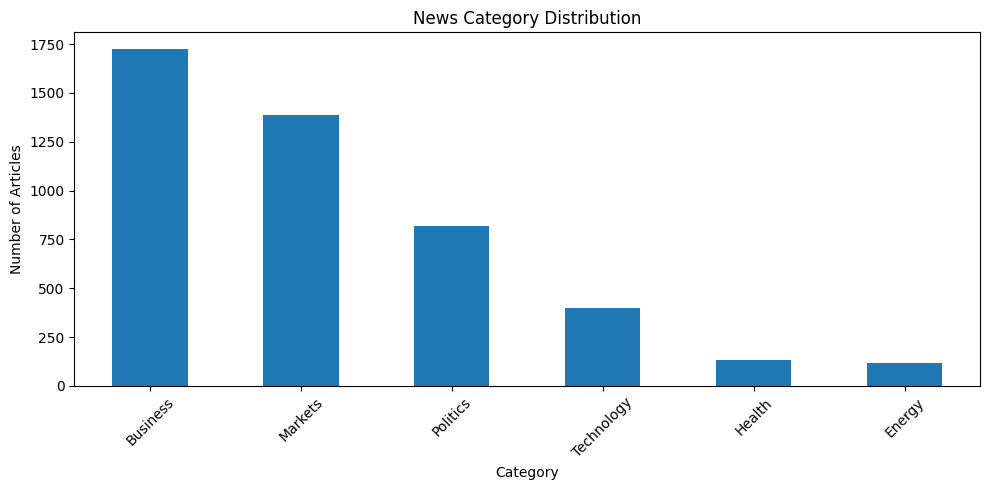

In [14]:
# ================================================================
# STEP 13: CATEGORY DISTRIBUTION
# ================================================================
# Purpose:
#   Visualize the number of articles in each original category.
# ================================================================

print("=" * 70)
print("STEP 13: CATEGORY DISTRIBUTION")
print("=" * 70)

category_counts = df["Category"].value_counts()

print(category_counts)

plt.figure(figsize=(10, 5))

category_counts.plot(
    kind="bar"
)

plt.title("News Category Distribution")
plt.xlabel("Category")
plt.ylabel("Number of Articles")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [15]:
# ================================================================
# STEP 14: LOAD SENTENCE TRANSFORMER
# ================================================================
# Purpose:
#   Load a pretrained language model that understands the
#   semantic meaning of news titles.
#
#   Model:
#       all-MiniLM-L6-v2
#
#   Output:
#       384-dimensional embedding for each title
# ================================================================

print("=" * 70)
print("STEP 14: LOADING SENTENCE TRANSFORMER")
print("=" * 70)

from sentence_transformers import SentenceTransformer

# Load pretrained sentence embedding model
embedding_model = SentenceTransformer(
    "all-MiniLM-L6-v2"
)

print("Model loaded successfully.")
print("Model: all-MiniLM-L6-v2")

STEP 14: LOADING SENTENCE TRANSFORMER


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Model loaded successfully.
Model: all-MiniLM-L6-v2


In [16]:
# ================================================================
# STEP 15: GENERATE NEWS TITLE EMBEDDINGS
# ================================================================
# Purpose:
#   Convert every news title into a numerical vector representing
#   its semantic meaning.
#
#   Example:
#
#       "OpenAI releases new AI model"
#                    ↓
#             Sentence Transformer
#                    ↓
#       [0.21, -0.14, 0.53, ..., 0.08]
#
#   Each title will have 384 numerical features.
# ================================================================

print("=" * 70)
print("STEP 15: GENERATING NEWS TITLE EMBEDDINGS")
print("=" * 70)

# Convert titles into a Python list
titles = df["Title"].tolist()

print("Number of titles:", len(titles))

# Generate embeddings
title_embeddings = embedding_model.encode(
    titles,

    # Process 64 titles at a time
    batch_size=64,

    # Display progress bar
    show_progress_bar=True,

    # Normalize embeddings for better similarity calculations
    normalize_embeddings=True
)

print("\nEmbedding generation completed.")

print("Embedding matrix shape:")
print(title_embeddings.shape)

STEP 15: GENERATING NEWS TITLE EMBEDDINGS
Number of titles: 4577


Batches:   0%|          | 0/72 [00:00<?, ?it/s]


Embedding generation completed.
Embedding matrix shape:
(4577, 384)


In [17]:
# ================================================================
# STEP 16: SAVE TITLE EMBEDDINGS
# ================================================================
# Purpose:
#   Save the generated embeddings so they can be reused later.
# ================================================================

import joblib

embedding_file = "news_title_embeddings.pkl"

joblib.dump(
    title_embeddings,
    embedding_file
)

print("Embeddings saved successfully.")
print("File:", embedding_file)
print("Shape:", title_embeddings.shape)

Embeddings saved successfully.
File: news_title_embeddings.pkl
Shape: (4577, 384)


In [18]:
# ================================================================
# STEP 17: DISCOVER NEW NEWS TOPICS
# ================================================================
# Purpose:
#   Automatically discover hidden groups/topics in the news
#   using semantic title embeddings.
#
#   IMPORTANT:
#       We KEEP the original Category.
#       We are adding topic_id, not replacing Category.
# ================================================================

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

print("=" * 70)
print("STEP 17: DISCOVERING NEW NEWS TOPICS")
print("=" * 70)

# Test different numbers of topics
cluster_range = range(6, 16)

silhouette_scores = []

for k in cluster_range:

    print(f"\nTesting K = {k}")

    # Create KMeans model
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    # Assign every article to a topic
    labels = kmeans.fit_predict(
        title_embeddings
    )

    # Calculate clustering quality
    score = silhouette_score(
        title_embeddings,
        labels
    )

    silhouette_scores.append(score)

    print(
        f"Silhouette Score: {score:.4f}"
    )

STEP 17: DISCOVERING NEW NEWS TOPICS

Testing K = 6
Silhouette Score: 0.0138

Testing K = 7
Silhouette Score: 0.0153

Testing K = 8
Silhouette Score: 0.0143

Testing K = 9
Silhouette Score: 0.0159

Testing K = 10
Silhouette Score: 0.0176

Testing K = 11
Silhouette Score: 0.0164

Testing K = 12
Silhouette Score: 0.0180

Testing K = 13
Silhouette Score: 0.0191

Testing K = 14
Silhouette Score: 0.0202

Testing K = 15
Silhouette Score: 0.0194


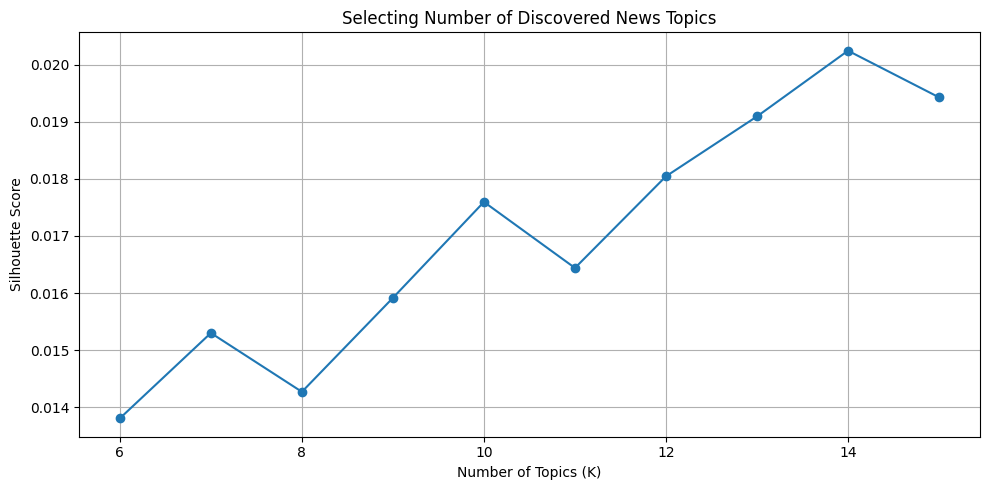

In [19]:
# ================================================================
# STEP 18: VISUALIZE TOPIC SELECTION
# ================================================================
# Purpose:
#   Visualize the Silhouette Score for each candidate number
#   of discovered topics.
# ================================================================

plt.figure(figsize=(10, 5))

plt.plot(
    list(cluster_range),
    silhouette_scores,
    marker="o"
)

plt.xlabel("Number of Topics (K)")
plt.ylabel("Silhouette Score")
plt.title("Selecting Number of Discovered News Topics")

plt.grid(True)
plt.tight_layout()

plt.show()

In [20]:
# ================================================================
# STEP 19: SELECT BEST NUMBER OF DISCOVERED TOPICS
# ================================================================
# Purpose:
#   Select the number of topics that produced the highest
#   Silhouette Score during Step 18.
#
#   Higher Silhouette Score generally indicates better-separated
#   and more internally consistent clusters.
# ================================================================

print("=" * 70)
print("STEP 19: SELECTING BEST NUMBER OF TOPICS")
print("=" * 70)

# Find the index of the highest Silhouette Score
best_index = np.argmax(silhouette_scores)

# Convert that index into the corresponding K value
BEST_K = list(cluster_range)[best_index]

# Get the best score
BEST_SILHOUETTE = silhouette_scores[best_index]

print(f"Best number of topics (K): {BEST_K}")
print(f"Best Silhouette Score: {BEST_SILHOUETTE:.4f}")

STEP 19: SELECTING BEST NUMBER OF TOPICS
Best number of topics (K): 14
Best Silhouette Score: 0.0202


In [21]:
# ================================================================
# STEP 20: TRAIN FINAL TOPIC CLUSTERING MODEL
# ================================================================
# Purpose:
#   Train the final KMeans model using the optimal number of
#   topics selected in Step 19.
#
#   The original Category is NOT replaced.
#   We are creating an additional topic_id feature.
# ================================================================

print("=" * 70)
print("STEP 20: TRAINING FINAL TOPIC MODEL")
print("=" * 70)

# Create the final KMeans clustering model
topic_model = KMeans(
    n_clusters=BEST_K,
    random_state=42,
    n_init=20
)

# Assign every news article to one discovered topic
topic_labels = topic_model.fit_predict(
    title_embeddings
)

# Store the discovered topic ID in the dataset
df["topic_id"] = topic_labels

print("Final KMeans topic model trained successfully.")

print("\nNumber of discovered topics:")
print(df["topic_id"].nunique())

print("\nArticles per discovered topic:")
print(
    df["topic_id"]
    .value_counts()
    .sort_index()
)

STEP 20: TRAINING FINAL TOPIC MODEL
Final KMeans topic model trained successfully.

Number of discovered topics:
14

Articles per discovered topic:
topic_id
0     365
1     459
2     232
3     388
4     361
5     209
6     576
7     469
8     250
9      79
10    281
11    249
12    572
13     87
Name: count, dtype: int64


In [22]:
# ================================================================
# STEP 21: INSPECT DISCOVERED TOPICS
# ================================================================
# Purpose:
#   Examine representative news titles from each discovered
#   topic and understand what each cluster represents.
# ================================================================

print("=" * 70)
print("STEP 21: INSPECTING DISCOVERED TOPICS")
print("=" * 70)

for topic_id in sorted(df["topic_id"].unique()):

    # Select all articles belonging to this topic
    topic_articles = df[
        df["topic_id"] == topic_id
    ]

    print("\n" + "=" * 80)
    print(f"TOPIC {topic_id}")
    print("=" * 80)

    print(
        "Number of articles:",
        len(topic_articles)
    )

    print("\nOriginal category distribution:")

    print(
        topic_articles["Category"]
        .value_counts()
        .head(10)
    )

    print("\nRepresentative news titles:")

    # Display a sample of titles from this topic
    display(
        topic_articles[
            ["Title", "Category"]
        ].head(15)
    )

STEP 21: INSPECTING DISCOVERED TOPICS

TOPIC 0
Number of articles: 365

Original category distribution:
Category
Business      188
Energy         67
Markets        59
Politics       32
Technology     13
Health          6
Name: count, dtype: int64

Representative news titles:


,Title,Category
27,Singapore lab-grown seafood startup to launch ...,Business
40,HondaJet completes US test flight powered by 1...,Energy
41,Eggshells and bamboo help make Honda and Toyot...,Business
45,Future US Food Security is a $3.2 Billion Oppo...,Business
47,Siren knee-deep in NZ drilling blitz at high-g...,Energy
53,Record gold grades for Aureka at Victorian gol...,Business
55,West Wits shifts first ore as South African go...,Business
58,Osmond lights up Spanish heavy minerals hunt w...,Business
69,Kansai Electric to conduct surveys for new nuc...,Energy
72,Lead Is Becoming More Common Among Protein Pow...,Health



TOPIC 1
Number of articles: 459

Original category distribution:
Category
Politics      264
Business       95
Markets        54
Technology     27
Energy         11
Health          8
Name: count, dtype: int64

Representative news titles:


,Title,Category
0,Vietnam Airlines data leak exposes a crisis of...,Technology
29,Coalition torn over super tax fight as budget ...,Politics
36,Hino to face life without Toyota's backing aft...,Business
43,Australia to stare down Trump’s threats over n...,Politics
54,Fox News joins mass rebellion over Pentagon’s ...,Politics
56,Election breaches skyrocket as AEC calls for m...,Politics
60,‘Major weakness’: No relief from SmartGate pai...,Politics
63,Coalition talks could bring Takaichi closer to...,Politics
80,Alex Jones’ $1.4 Billion Defamation Loss Stand...,Politics
99,Luxxfolio Appoints Dustin Zinger as Strategic ...,Business



TOPIC 2
Number of articles: 232

Original category distribution:
Category
Health        97
Business      74
Technology    27
Markets       21
Politics      12
Energy         1
Name: count, dtype: int64

Representative news titles:


...

,Title,Category
32,DJI appeals US ruling upholding designation as...,Politics
35,Japan to ban cryptocurrency insider trading wi...,Politics
38,Wall Street ends mixed as US-China trade war p...,Business
42,US charges Cambodian executive in massive cryp...,Politics
52,BHP boss defends China ties amid iron ore ban ...,Business
59,A new ocean front opens in Trump’s trade wars,Politics
64,Trump’s trade hostilities unite Lula and Modi ...,Politics
65,Japan turns to anti-dumping measures as intern...,Politics
67,Chinese airlines oppose Trump plan to ban flyi...,Politics
68,EU considers forced tech transfers for Chinese...,Politics



TOPIC 12
Number of articles: 572

Original category distribution:
Category
Business      330
Technology    144
Markets        60
Politics       32
Energy          3
Health          3
Name: count, dtype: int64

Representative news titles:


,Title,Category
2,Think It's Too Late to Buy IonQ? Here's the 1 ...,Markets
3,Intel's Crucial Panther Lake Chips Start Produ...,Technology
5,Think It's Too Late to Buy Applied Digital? He...,Markets
22,Where Will Rocket Lab Be in 5 Years? My Best G...,Business
37,Vietnam's new airline aims to make local islan...,Business
50,Eclipse eyes NASDAQ dual listing to underpin U...,Markets
62,Education technology on rise in Japan to ease ...,Technology
70,Waymo Taps London As Its First Overseas Robota...,Technology
77,Walmart Partners With OpenAI Allowing Shoppers...,Technology
100,Canamera Announces Engagement of Rangefront fo...,Energy



TOPIC 13
Number of articles: 87

Original category distribution:
Category
Politics      71
Business      10
Markets        4
Technology     2
Name: count, dtype: int64

Representative news titles:


,Title,Category
25,Talks begin over second phase of Trump's Israe...,Politics
26,"Israel says bodies of Uriel Baruch, Tamir Nimr...",Politics
39,Israel and its allies must pay the cost of reb...,Politics
66,Ukraine raises alarm over foreign components i...,Politics
205,Why the US could not shake off the Middle East,Politics
217,1949086/Palestinian Authority Says It Is Ready...,Politics
219,1949067/600 Aid Trucks To Be Allowed Into Gaza...,Politics
220,1949070/Israeli Tank Fire Reported In Northern...,Politics
223,1948998/Dr Congo Rebel Group Sign Truce Monito...,Politics
242,Israel says it has received remains of four mo...,Politics


In [23]:
# ================================================================
# STEP 22: CREATE DISCOVERED TOPIC SUMMARY
# ================================================================
# Purpose:
#   Summarize the size and dominant original category of each
#   automatically discovered topic.
# ================================================================

print("=" * 70)
print("STEP 22: TOPIC SUMMARY")
print("=" * 70)

topic_summary = (
    df.groupby("topic_id")
      .agg(
          article_count=("Title", "count"),

          # Find the most common original category
          dominant_category=(
              "Category",
              lambda x: x.value_counts().index[0]
          )
      )
      .reset_index()
)

display(topic_summary)

STEP 22: TOPIC SUMMARY


,topic_id,article_count,dominant_category
0,0,365,Business
1,1,459,Politics
2,2,232,Health
3,3,388,Business
4,4,361,Markets
5,5,209,Business
6,6,576,Business
7,7,469,Markets
8,8,250,Technology
9,9,79,Politics


In [24]:
# ================================================================
# STEP 23: TOPIC VS ORIGINAL CATEGORY
# ================================================================
# Purpose:
#   Analyze how the automatically discovered topics relate to
#   the original human-provided categories.
# ================================================================

print("=" * 70)
print("STEP 23: TOPIC VS ORIGINAL CATEGORY")
print("=" * 70)

topic_category_table = pd.crosstab(
    df["topic_id"],
    df["Category"]
)

display(topic_category_table)

STEP 23: TOPIC VS ORIGINAL CATEGORY


Category,Business,Energy,Health,Markets,Politics,Technology
topic_id,,,,,,
0,188,67,6,59,32,13
1,95,11,8,54,264,27
2,74,1,97,21,12,27
3,179,2,1,108,88,10
4,44,3,0,304,5,5
5,111,1,2,89,3,3
6,338,4,5,205,18,6
7,103,19,8,272,60,7
8,66,0,1,28,10,145


STEP 24: DISCOVERED TOPIC DISTRIBUTION


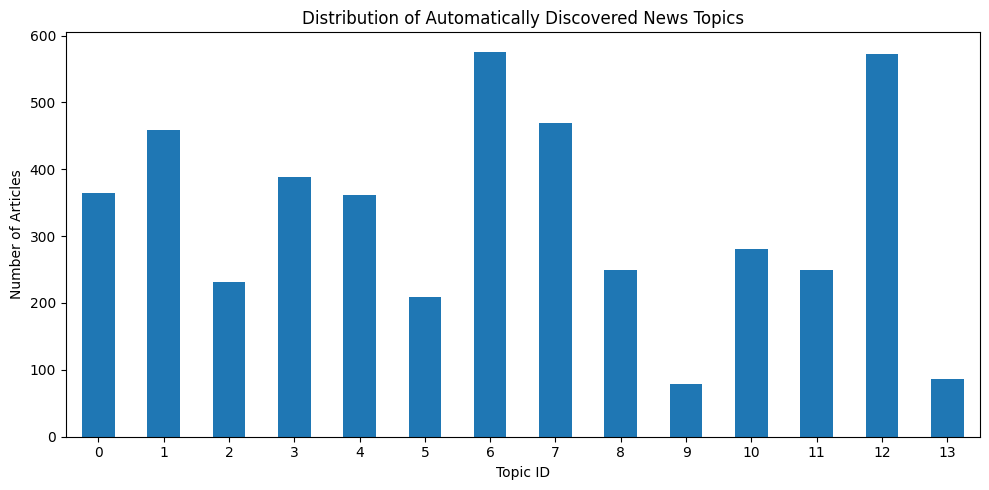

In [25]:
# ================================================================
# STEP 24: DISCOVERED TOPIC DISTRIBUTION
# ================================================================
# Purpose:
#   Visualize the number of news articles assigned to each
#   automatically discovered topic.
# ================================================================

print("=" * 70)
print("STEP 24: DISCOVERED TOPIC DISTRIBUTION")
print("=" * 70)

topic_counts = (
    df["topic_id"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(10, 5))

topic_counts.plot(
    kind="bar"
)

plt.title("Distribution of Automatically Discovered News Topics")
plt.xlabel("Topic ID")
plt.ylabel("Number of Articles")

plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [28]:
# ================================================================
# STEP 25: CREATE SYNTHETIC USERS WITH INTEREST PROFILES
# ================================================================
# Purpose:
#   Simulate 10 users, each with a preferred set of news categories.
#   This is the "ground truth" the RL agents will have to discover
#   through trial and error (they will NOT see this dict directly).
# ================================================================

import random
random.seed(42)
np.random.seed(42)

print("=" * 70)
print("STEP 25: CREATING SYNTHETIC USER PROFILES")
print("=" * 70)

all_categories = sorted(df["Category"].unique().tolist())
print(f"\nAvailable categories ({len(all_categories)}):")
print(all_categories)

NUM_USERS = 10

# Each user gets 2-3 preferred categories (their "taste"),
# with one primary (dominant) interest and 1-2 secondary interests.
user_profiles = {}

for user_id in range(NUM_USERS):
    prefs = random.sample(all_categories, k=min(3, len(all_categories)))
    primary = prefs[0]
    secondary = prefs[1:]

    user_profiles[user_id] = {
        "primary_interest": primary,
        "secondary_interests": secondary,
        # click probability if recommended article matches primary interest
        "p_click_primary": np.random.uniform(0.75, 0.90),
        # click probability if it matches a secondary interest
        "p_click_secondary": np.random.uniform(0.35, 0.55),
        # click probability if it matches nothing they like (noise clicks)
        "p_click_random": np.random.uniform(0.02, 0.08),
    }

print("\nUser profiles created:\n")
for uid, prof in user_profiles.items():
    print(f"User {uid}: PRIMARY = {prof['primary_interest']:15s} | "
          f"SECONDARY = {prof['secondary_interests']} | "
          f"p(click|primary)={prof['p_click_primary']:.2f}")

STEP 25: CREATING SYNTHETIC USER PROFILES

Available categories (6):
['Business', 'Energy', 'Health', 'Markets', 'Politics', 'Technology']

User profiles created:

User 0: PRIMARY = Technology      | SECONDARY = ['Business', 'Politics'] | p(click|primary)=0.81
User 1: PRIMARY = Technology      | SECONDARY = ['Health', 'Energy'] | p(click|primary)=0.84
User 2: PRIMARY = Energy          | SECONDARY = ['Technology', 'Business'] | p(click|primary)=0.76
User 3: PRIMARY = Technology      | SECONDARY = ['Politics', 'Business'] | p(click|primary)=0.86
User 4: PRIMARY = Politics        | SECONDARY = ['Markets', 'Business'] | p(click|primary)=0.87
User 5: PRIMARY = Business        | SECONDARY = ['Technology', 'Energy'] | p(click|primary)=0.78
User 6: PRIMARY = Energy          | SECONDARY = ['Politics', 'Business'] | p(click|primary)=0.81
User 7: PRIMARY = Politics        | SECONDARY = ['Energy', 'Markets'] | p(click|primary)=0.77
User 8: PRIMARY = Energy          | SECONDARY = ['Markets', 'Healt

In [29]:
# ================================================================
# STEP 26: RL ENVIRONMENT — SIMULATED USER CLICK BEHAVIOR
# ================================================================
# Purpose:
#   This is the "world" our RL agents interact with.
#   Given a user and a recommended category, it returns a reward
#   (1 = clicked, 0 = ignored) sampled from that user's true
#   (hidden) preference profile.
# ================================================================

print("=" * 70)
print("STEP 26: BUILDING RL ENVIRONMENT")
print("=" * 70)

NUM_CATEGORIES = len(all_categories)
category_to_idx = {c: i for i, c in enumerate(all_categories)}
idx_to_category = {i: c for c, i in category_to_idx.items()}

def get_reward(user_id, category):
    """Simulate whether a user clicks a recommended category."""
    profile = user_profiles[user_id]
    if category == profile["primary_interest"]:
        p = profile["p_click_primary"]
    elif category in profile["secondary_interests"]:
        p = profile["p_click_secondary"]
    else:
        p = profile["p_click_random"]
    return int(np.random.rand() < p)

def oracle_reward(user_id):
    """Best possible expected reward for this user (always picks primary)."""
    return user_profiles[user_id]["p_click_primary"]

NUM_ROUNDS = 3000  # simulated recommendation interactions

print(f"Categories (arms): {NUM_CATEGORIES}")
print(f"Users (contexts): {NUM_USERS}")
print(f"Simulated rounds per model: {NUM_ROUNDS}")

STEP 26: BUILDING RL ENVIRONMENT
Categories (arms): 6
Users (contexts): 10
Simulated rounds per model: 3000


In [30]:
# ================================================================
# STEP 27: GENERIC EXPERIMENT RUNNER
# ================================================================
# Purpose:
#   Every RL algorithm plugs into this same loop so comparisons
#   are fair. An "agent" just needs select_action() and update().
# ================================================================

print("=" * 70)
print("STEP 27: EXPERIMENT RUNNER")
print("=" * 70)

results = {}  # model_name -> dict with reward_history, cumulative_reward, regret_history

def run_experiment(agent, model_name, num_rounds=NUM_ROUNDS):
    np.random.seed(0)
    random.seed(0)

    reward_history = []
    regret_history = []
    cumulative_reward = 0.0
    cumulative_regret = 0.0

    for t in range(num_rounds):
        user_id = random.randint(0, NUM_USERS - 1)

        action_idx = agent.select_action(user_id)
        category = idx_to_category[action_idx]

        reward = get_reward(user_id, category)
        agent.update(user_id, action_idx, reward)

        cumulative_reward += reward
        cumulative_regret += (oracle_reward(user_id) - reward)

        reward_history.append(reward)
        regret_history.append(cumulative_regret)

    results[model_name] = {
        "reward_history": reward_history,
        "cumulative_reward": np.cumsum(reward_history),
        "regret_history": regret_history,
        "final_ctr": np.mean(reward_history[-500:]),  # CTR over last 500 rounds
        "total_reward": sum(reward_history),
    }

    print(f"{model_name:20s} | Total reward: {sum(reward_history):5d} / {num_rounds} "
          f"| Final-500 CTR: {results[model_name]['final_ctr']:.3f} "
          f"| Final regret: {cumulative_regret:.1f}")

    return results[model_name]

STEP 27: EXPERIMENT RUNNER


In [31]:
# ================================================================
# STEP 28: MODEL 1 (RANDOM) & MODEL 2 (EPSILON-GREEDY)
# ================================================================

print("=" * 70)
print("STEP 28: RANDOM BASELINE & EPSILON-GREEDY BANDIT")
print("=" * 70)

class RandomAgent:
    """Sanity-check baseline: recommends a random category every time."""
    def select_action(self, user_id):
        return random.randint(0, NUM_CATEGORIES - 1)
    def update(self, user_id, action_idx, reward):
        pass  # doesn't learn

class EpsilonGreedyAgent:
    """
    Classic exploration-exploitation bandit.
    Maintains a separate estimate table per (user, category).
    With probability epsilon: explore randomly.
    Otherwise: exploit the category with highest known average reward.
    """
    def __init__(self, epsilon=0.1):
        self.epsilon = epsilon
        self.counts = np.zeros((NUM_USERS, NUM_CATEGORIES))
        self.values = np.zeros((NUM_USERS, NUM_CATEGORIES))

    def select_action(self, user_id):
        if np.random.rand() < self.epsilon:
            return random.randint(0, NUM_CATEGORIES - 1)
        return int(np.argmax(self.values[user_id]))

    def update(self, user_id, action_idx, reward):
        self.counts[user_id, action_idx] += 1
        n = self.counts[user_id, action_idx]
        old_value = self.values[user_id, action_idx]
        # incremental average update
        self.values[user_id, action_idx] = old_value + (reward - old_value) / n

run_experiment(RandomAgent(), "Random Baseline")
run_experiment(EpsilonGreedyAgent(epsilon=0.1), "Epsilon-Greedy (e=0.1)")

STEP 28: RANDOM BASELINE & EPSILON-GREEDY BANDIT
Random Baseline      | Total reward:   896 / 3000 | Final-500 CTR: 0.314 | Final regret: 1546.0
Epsilon-Greedy (e=0.1) | Total reward:  1840 / 3000 | Final-500 CTR: 0.712 | Final regret: 600.9


{'reward_history': [0,
  0,
  0,
  0,
  0,
  0,
  0,
  1,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  1,
  0,
  0,
  1,
  0,
  0,
  0,
  0,
  1,
  0,
  0,
  0,
  1,
  1,
  1,
  1,
  1,
  0,
  0,
  0,
  0,
  0,
  1,
  0,
  1,
  0,
  0,
  1,
  1,
  0,
  1,
  0,
  1,
  1,
  1,
  1,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  1,
  0,
  0,
  0,
  0,
  1,
  0,
  1,
  1,
  0,
  0,
  1,
  1,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  1,
  1,
  0,
  0,
  0,
  1,
  1,
  1,
  1,
  0,
  0,
  1,
  0,
  1,
  0,
  0,
  1,
  1,
  0,
  1,
  1,
  1,
  1,
  1,
  0,
  0,
  0,
  1,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  1,
  0,
  1,
  1,
  1,
  1,
  0,
  1,
  1,
  1,
  0,
  1,
  0,
  0,
  1,
  0,
  1,
  0,
  0,
  1,
  1,
  1,
  0,
  0,
  0,
  0,
  0,
  0,
  1,
  1,
  1,
  0,
  0,
  1,
  1,
  0,
  0,
  1,
  0,
  1,
  0,
  1,
  0,
  0,
  1,
  0,
  0,
  1,
  0,
  1,
  0,
  1,
  1,
  0,
  0,
  1,
  1,
  1,
  1,
  1,
  1,
  0,
  1,
  0,
  0,
  1,
  0,
  0,
  1,
  0,
  1,
  1,
  1,
  0,
  1,
  0,
  0,
  1,
  0,
  0,
  0,
  0,
  0,
  

In [32]:
# ================================================================
# STEP 29: MODEL 3 — UCB1 (UPPER CONFIDENCE BOUND)
# ================================================================
# Purpose:
#   Instead of random exploration, UCB explores categories it's
#   UNCERTAIN about (few tries so far), and exploits ones with
#   strong track records. Generally more sample-efficient than
#   epsilon-greedy.
# ================================================================

print("=" * 70)
print("STEP 29: UCB1 BANDIT")
print("=" * 70)

class UCB1Agent:
    def __init__(self, c=2.0):
        self.c = c  # exploration strength
        self.counts = np.zeros((NUM_USERS, NUM_CATEGORIES))
        self.values = np.zeros((NUM_USERS, NUM_CATEGORIES))
        self.total_counts = np.zeros(NUM_USERS)

    def select_action(self, user_id):
        # Try every category at least once first
        untried = np.where(self.counts[user_id] == 0)[0]
        if len(untried) > 0:
            return int(untried[0])

        total = self.total_counts[user_id]
        ucb_scores = self.values[user_id] + self.c * np.sqrt(
            np.log(total) / self.counts[user_id]
        )
        return int(np.argmax(ucb_scores))

    def update(self, user_id, action_idx, reward):
        self.counts[user_id, action_idx] += 1
        self.total_counts[user_id] += 1
        n = self.counts[user_id, action_idx]
        old_value = self.values[user_id, action_idx]
        self.values[user_id, action_idx] = old_value + (reward - old_value) / n

run_experiment(UCB1Agent(c=2.0), "UCB1")

STEP 29: UCB1 BANDIT
UCB1                 | Total reward:  1713 / 3000 | Final-500 CTR: 0.648 | Final regret: 727.4


{'reward_history': [0,
  1,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  1,
  1,
  0,
  1,
  0,
  0,
  1,
  1,
  0,
  0,
  0,
  0,
  0,
  1,
  0,
  1,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  1,
  0,
  1,
  0,
  1,
  0,
  0,
  0,
  1,
  0,
  0,
  1,
  0,
  0,
  0,
  0,
  0,
  1,
  1,
  0,
  0,
  1,
  1,
  0,
  0,
  1,
  0,
  1,
  1,
  1,
  1,
  1,
  1,
  0,
  1,
  1,
  0,
  1,
  0,
  0,
  0,
  0,
  0,
  1,
  0,
  1,
  1,
  0,
  1,
  0,
  1,
  0,
  0,
  1,
  0,
  1,
  0,
  0,
  1,
  0,
  0,
  1,
  1,
  1,
  0,
  1,
  0,
  1,
  0,
  1,
  0,
  0,
  0,
  0,
  1,
  0,
  0,
  0,
  0,
  0,
  0,
  1,
  1,
  0,
  0,
  0,
  0,
  0,
  0,
  1,
  0,
  1,
  0,
  0,
  1,
  1,
  1,
  1,
  0,
  0,
  1,
  1,
  0,
  0,
  1,
  0,
  0,
  1,
  0,
  0,
  0,
  0,
  0,
  1,
  0,
  0,
  0,
  0,
  1,
  0,
  1,
  1,
  1,
  0,
  0,
  1,
  0,
  0,
  0,
  0,
  1,
  0,
  0,
  1,
  1,
  0,
  0,
  1,
  0,
  1,
  1,
  1,
  0,
  1,
  0,
  0,
  1,
  1,
  1,
  0,
  0,
  1,
  0,
  1,
  0,
  0,
  0,
  1,
  1,
  1,
  1,
  0,
  1,
  1,
  

In [33]:
# ================================================================
# STEP 30: MODEL 4 — THOMPSON SAMPLING (BAYESIAN BANDIT)
# ================================================================
# Purpose:
#   Maintains a Beta distribution (alpha=successes, beta=failures)
#   per (user, category). At each round, SAMPLES a click-probability
#   from each category's belief distribution and picks the highest
#   sample. This naturally balances explore/exploit and is usually
#   the strongest classic bandit algorithm.
# ================================================================

print("=" * 70)
print("STEP 30: THOMPSON SAMPLING BANDIT")
print("=" * 70)

class ThompsonSamplingAgent:
    def __init__(self):
        self.alpha = np.ones((NUM_USERS, NUM_CATEGORIES))  # successes + 1
        self.beta = np.ones((NUM_USERS, NUM_CATEGORIES))   # failures + 1

    def select_action(self, user_id):
        samples = np.random.beta(self.alpha[user_id], self.beta[user_id])
        return int(np.argmax(samples))

    def update(self, user_id, action_idx, reward):
        if reward == 1:
            self.alpha[user_id, action_idx] += 1
        else:
            self.beta[user_id, action_idx] += 1

run_experiment(ThompsonSamplingAgent(), "Thompson Sampling")

STEP 30: THOMPSON SAMPLING BANDIT
Thompson Sampling    | Total reward:  2305 / 3000 | Final-500 CTR: 0.810 | Final regret: 135.4


{'reward_history': [0,
  1,
  1,
  1,
  0,
  0,
  0,
  1,
  0,
  0,
  0,
  1,
  1,
  0,
  0,
  1,
  1,
  0,
  1,
  0,
  1,
  1,
  0,
  1,
  0,
  0,
  0,
  0,
  0,
  0,
  1,
  1,
  0,
  0,
  0,
  0,
  0,
  1,
  0,
  0,
  1,
  0,
  0,
  1,
  0,
  1,
  0,
  1,
  1,
  0,
  0,
  0,
  1,
  0,
  1,
  0,
  1,
  1,
  0,
  0,
  0,
  0,
  1,
  0,
  0,
  1,
  0,
  1,
  1,
  1,
  1,
  1,
  0,
  1,
  0,
  1,
  1,
  1,
  1,
  1,
  0,
  1,
  1,
  1,
  1,
  1,
  1,
  0,
  1,
  0,
  0,
  1,
  1,
  1,
  1,
  0,
  1,
  1,
  0,
  1,
  0,
  1,
  1,
  0,
  1,
  0,
  0,
  1,
  0,
  0,
  1,
  0,
  1,
  1,
  1,
  0,
  0,
  0,
  1,
  1,
  0,
  1,
  1,
  1,
  0,
  1,
  1,
  0,
  1,
  0,
  1,
  0,
  0,
  0,
  1,
  1,
  1,
  1,
  0,
  1,
  1,
  0,
  1,
  1,
  1,
  0,
  1,
  1,
  1,
  0,
  1,
  1,
  1,
  1,
  0,
  1,
  0,
  1,
  1,
  1,
  1,
  0,
  0,
  1,
  1,
  1,
  0,
  0,
  1,
  0,
  1,
  1,
  1,
  0,
  1,
  1,
  1,
  1,
  0,
  0,
  1,
  1,
  0,
  1,
  1,
  0,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  0,
  1,
  1,
  

In [34]:
# ================================================================
# STEP 31: CATEGORY CONTEXT VECTORS (for contextual bandit)
# ================================================================
# Purpose:
#   LinUCB needs a numeric "context" describing each action (category).
#   We build this from your existing title embeddings: the average
#   embedding of all articles in a category becomes that category's
#   semantic fingerprint. We PCA-reduce it to keep things fast.
# ================================================================

from sklearn.decomposition import PCA

print("=" * 70)
print("STEP 31: BUILDING CATEGORY CONTEXT VECTORS")
print("=" * 70)

# Reduce 384-dim embeddings to 10 dims (fast + still informative)
PCA_DIM = 10
pca = PCA(n_components=PCA_DIM, random_state=42)
reduced_embeddings = pca.fit_transform(title_embeddings)

print(f"Explained variance (10 components): {pca.explained_variance_ratio_.sum():.3f}")

# Average embedding per category = that category's "semantic fingerprint"
category_vectors = {}
for cat in all_categories:
    mask = (df["Category"] == cat).values
    category_vectors[cat] = reduced_embeddings[mask].mean(axis=0)

print("\nCategory context vectors built:")
for cat, vec in category_vectors.items():
    print(f"  {cat:15s} -> shape {vec.shape}")

CONTEXT_DIM = NUM_USERS + PCA_DIM  # user one-hot + category embedding

def build_context(user_id, category):
    user_onehot = np.zeros(NUM_USERS)
    user_onehot[user_id] = 1.0
    return np.concatenate([user_onehot, category_vectors[category]])

print(f"\nTotal context dimension: {CONTEXT_DIM}")

STEP 31: BUILDING CATEGORY CONTEXT VECTORS
Explained variance (10 components): 0.207

Category context vectors built:
  Business        -> shape (10,)
  Energy          -> shape (10,)
  Health          -> shape (10,)
  Markets         -> shape (10,)
  Politics        -> shape (10,)
  Technology      -> shape (10,)

Total context dimension: 20


In [35]:
# ================================================================
# STEP 32: MODEL 5 — LinUCB (CONTEXTUAL BANDIT)
# ================================================================
# Purpose:
#   Unlike UCB1/Thompson (which treat each user independently),
#   LinUCB learns a SHARED linear relationship between context
#   features (embeddings + user identity) and reward. This lets
#   it generalize: knowledge learned from one user's clicks on
#   "Technology" articles can inform predictions for a similar user.
# ================================================================

print("=" * 70)
print("STEP 32: LinUCB CONTEXTUAL BANDIT")
print("=" * 70)

class LinUCBAgent:
    def __init__(self, n_arms, context_dim, alpha=1.0):
        self.n_arms = n_arms
        self.d = context_dim
        self.alpha = alpha
        # Disjoint LinUCB: separate A, b per arm
        self.A = [np.identity(self.d) for _ in range(n_arms)]
        self.b = [np.zeros(self.d) for _ in range(n_arms)]

    def select_action(self, user_id):
        scores = []
        for a in range(self.n_arms):
            category = idx_to_category[a]
            x = build_context(user_id, category)
            A_inv = np.linalg.inv(self.A[a])
            theta = A_inv @ self.b[a]
            mean = theta @ x
            confidence = self.alpha * np.sqrt(x @ A_inv @ x)
            scores.append(mean + confidence)
        return int(np.argmax(scores))

    def update(self, user_id, action_idx, reward):
        category = idx_to_category[action_idx]
        x = build_context(user_id, category)
        self.A[action_idx] += np.outer(x, x)
        self.b[action_idx] += reward * x

run_experiment(LinUCBAgent(n_arms=NUM_CATEGORIES, context_dim=CONTEXT_DIM, alpha=1.0), "LinUCB")

STEP 32: LinUCB CONTEXTUAL BANDIT
LinUCB               | Total reward:  2339 / 3000 | Final-500 CTR: 0.814 | Final regret: 101.4


{'reward_history': [0,
  0,
  1,
  0,
  0,
  0,
  0,
  0,
  0,
  1,
  0,
  1,
  0,
  0,
  0,
  0,
  1,
  0,
  0,
  0,
  0,
  0,
  0,
  1,
  1,
  0,
  0,
  0,
  1,
  0,
  1,
  0,
  1,
  1,
  1,
  0,
  0,
  0,
  0,
  1,
  0,
  1,
  1,
  1,
  1,
  0,
  0,
  0,
  1,
  0,
  1,
  1,
  0,
  1,
  1,
  1,
  0,
  0,
  1,
  1,
  1,
  0,
  0,
  1,
  0,
  1,
  0,
  1,
  0,
  1,
  0,
  1,
  0,
  1,
  0,
  1,
  1,
  1,
  0,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  0,
  0,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  0,
  1,
  1,
  1,
  1,
  0,
  1,
  1,
  0,
  1,
  1,
  0,
  1,
  0,
  1,
  1,
  1,
  1,
  0,
  1,
  0,
  0,
  1,
  1,
  0,
  0,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  0,
  1,
  0,
  0,
  1,
  1,
  1,
  0,
  1,
  1,
  0,
  1,
  1,
  1,
  0,
  0,
  0,
  1,
  0,
  1,
  1,
  1,
  0,
  0,
  1,
  0,
  1,
  1,
  1,
  1,
  0,
  0,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  0,
  1,
  0,
  0,
  1,
  1,
  1,
  1,
  1,
  1,
  0,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  0,
  1,
  0,
  

In [36]:
# ================================================================
# STEP 33: MODEL 6 — TABULAR Q-LEARNING
# ================================================================
# Purpose:
#   The classic RL algorithm. Maintains a Q-table Q[user, category]
#   estimating expected reward. Updates using the Q-learning rule:
#       Q(s,a) <- Q(s,a) + lr * (reward - Q(s,a))
#   (No next-state term since this is a single-step bandit episode,
#   but this is the same update rule used in full sequential RL.)
# ================================================================

print("=" * 70)
print("STEP 33: TABULAR Q-LEARNING")
print("=" * 70)

class QLearningAgent:
    def __init__(self, lr=0.1, epsilon=0.15, epsilon_decay=0.999, min_epsilon=0.02):
        self.lr = lr
        self.epsilon = epsilon
        self.epsilon_decay = epsilon_decay
        self.min_epsilon = min_epsilon
        self.Q = np.zeros((NUM_USERS, NUM_CATEGORIES))

    def select_action(self, user_id):
        if np.random.rand() < self.epsilon:
            action = random.randint(0, NUM_CATEGORIES - 1)
        else:
            action = int(np.argmax(self.Q[user_id]))
        self.epsilon = max(self.min_epsilon, self.epsilon * self.epsilon_decay)
        return action

    def update(self, user_id, action_idx, reward):
        td_target = reward  # single-step episodic bandit (no next state)
        td_error = td_target - self.Q[user_id, action_idx]
        self.Q[user_id, action_idx] += self.lr * td_error

run_experiment(QLearningAgent(lr=0.1, epsilon=0.15), "Q-Learning")

STEP 33: TABULAR Q-LEARNING
Q-Learning           | Total reward:  1873 / 3000 | Final-500 CTR: 0.686 | Final regret: 567.3


{'reward_history': [0,
  0,
  0,
  0,
  0,
  0,
  0,
  1,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  1,
  0,
  0,
  0,
  1,
  0,
  0,
  0,
  1,
  0,
  1,
  1,
  1,
  0,
  0,
  0,
  0,
  1,
  1,
  0,
  0,
  0,
  1,
  1,
  1,
  0,
  1,
  1,
  0,
  0,
  0,
  1,
  1,
  1,
  0,
  0,
  0,
  1,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  1,
  1,
  1,
  1,
  0,
  0,
  0,
  1,
  1,
  0,
  1,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  1,
  0,
  1,
  1,
  1,
  0,
  1,
  0,
  1,
  1,
  0,
  1,
  1,
  0,
  0,
  1,
  0,
  1,
  0,
  1,
  1,
  0,
  1,
  1,
  0,
  0,
  0,
  0,
  0,
  0,
  1,
  0,
  1,
  1,
  1,
  1,
  1,
  1,
  0,
  1,
  0,
  0,
  0,
  1,
  0,
  0,
  0,
  1,
  0,
  1,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  1,
  1,
  0,
  0,
  0,
  1,
  0,
  0,
  0,
  0,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  0,
  0,
  1,
  1,
  1,
  0,
  1,
  0,
  0,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  0,
  1,
  1,
  1,
  1,
  0,
  0,
  0,
  1,
  1,
  0,
  1,
  1,
  1,
  0,
  1,
  0,
  0,
  0,
  1,
  1,
  0,
  

In [37]:
# ================================================================
# STEP 34: MODEL 7 — DEEP Q-NETWORK (DQN)
# ================================================================
# Purpose:
#   Replaces the Q-table with a small neural network that takes
#   the user's context (one-hot + their click history so far) and
#   outputs a Q-value for every category. This is the deep-RL
#   flagship of the comparison.
# ================================================================

import torch
import torch.nn as nn
import torch.optim as optim
from collections import deque

print("=" * 70)
print("STEP 34: DEEP Q-NETWORK (DQN)")
print("=" * 70)

torch.manual_seed(42)

class QNetwork(nn.Module):
    def __init__(self, input_dim, output_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 32),
            nn.ReLU(),
            nn.Linear(32, 32),
            nn.ReLU(),
            nn.Linear(32, output_dim)
        )
    def forward(self, x):
        return self.net(x)

class DQNAgent:
    def __init__(self, n_users, n_arms, lr=0.01, epsilon=0.15,
                 epsilon_decay=0.999, min_epsilon=0.02,
                 batch_size=32, buffer_size=2000):
        self.n_arms = n_arms
        self.epsilon = epsilon
        self.epsilon_decay = epsilon_decay
        self.min_epsilon = min_epsilon
        self.batch_size = batch_size

        self.q_net = QNetwork(n_users, n_arms)
        self.optimizer = optim.Adam(self.q_net.parameters(), lr=lr)
        self.loss_fn = nn.MSELoss()

        self.buffer = deque(maxlen=buffer_size)
        self.n_users = n_users

    def _state(self, user_id):
        s = torch.zeros(self.n_users)
        s[user_id] = 1.0
        return s

    def select_action(self, user_id):
        if np.random.rand() < self.epsilon:
            action = random.randint(0, self.n_arms - 1)
        else:
            with torch.no_grad():
                q_values = self.q_net(self._state(user_id))
                action = int(torch.argmax(q_values).item())
        self.epsilon = max(self.min_epsilon, self.epsilon * self.epsilon_decay)
        return action

    def update(self, user_id, action_idx, reward):
        self.buffer.append((user_id, action_idx, reward))

        if len(self.buffer) < self.batch_size:
            return  # wait until we have enough samples

        batch = random.sample(self.buffer, self.batch_size)
        states = torch.stack([self._state(u) for u, a, r in batch])
        actions = torch.tensor([a for u, a, r in batch])
        rewards = torch.tensor([float(r) for u, a, r in batch])

        q_values = self.q_net(states)
        q_pred = q_values.gather(1, actions.unsqueeze(1)).squeeze(1)

        loss = self.loss_fn(q_pred, rewards)  # bandit: target = immediate reward
        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()

run_experiment(DQNAgent(n_users=NUM_USERS, n_arms=NUM_CATEGORIES), "DQN")

STEP 34: DEEP Q-NETWORK (DQN)
DQN                  | Total reward:  2133 / 3000 | Final-500 CTR: 0.788 | Final regret: 311.7


{'reward_history': [0,
  0,
  0,
  0,
  0,
  0,
  0,
  1,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  1,
  1,
  0,
  0,
  0,
  1,
  1,
  0,
  1,
  0,
  1,
  0,
  0,
  0,
  1,
  0,
  0,
  1,
  0,
  1,
  0,
  1,
  1,
  0,
  1,
  0,
  0,
  0,
  0,
  1,
  1,
  1,
  1,
  0,
  0,
  0,
  0,
  0,
  1,
  1,
  0,
  0,
  1,
  1,
  0,
  0,
  1,
  1,
  0,
  1,
  1,
  1,
  1,
  0,
  0,
  0,
  0,
  0,
  0,
  1,
  1,
  1,
  0,
  0,
  0,
  0,
  1,
  1,
  1,
  1,
  0,
  1,
  1,
  1,
  0,
  1,
  1,
  0,
  0,
  1,
  0,
  1,
  0,
  1,
  0,
  1,
  0,
  1,
  1,
  0,
  1,
  1,
  0,
  1,
  0,
  1,
  0,
  0,
  1,
  1,
  0,
  1,
  1,
  1,
  0,
  1,
  1,
  0,
  0,
  1,
  0,
  1,
  1,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  1,
  0,
  0,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  0,
  0,
  0,
  1,
  1,
  1,
  1,
  1,
  0,
  1,
  0,
  1,
  1,
  1,
  1,
  0,
  1,
  1,
  0,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  0,
  1,
  0,
  0,
  1,
  0,
  0,
  1,
  1,
  1,
  1,
  1,
  0,
  1,
  0,
  0,
  1,
  1,
  0,
  1,
  1,
  0,
  

In [38]:
# ================================================================
# STEP 35: FULL MODEL COMPARISON TABLE
# ================================================================
print("=" * 70)
print("STEP 35: FINAL MODEL COMPARISON")
print("=" * 70)

comparison_df = pd.DataFrame({
    "Model": list(results.keys()),
    "Total Reward": [results[m]["total_reward"] for m in results],
    "Final-500 CTR": [results[m]["final_ctr"] for m in results],
    "Final Regret": [results[m]["regret_history"][-1] for m in results],
}).sort_values("Total Reward", ascending=False).reset_index(drop=True)

comparison_df.insert(0, "Rank", range(1, len(comparison_df) + 1))

print(comparison_df.to_string(index=False))

BEST_MODEL_NAME = comparison_df.iloc[0]["Model"]
print(f"\n🏆 Best performing model: {BEST_MODEL_NAME}")

STEP 35: FINAL MODEL COMPARISON
 Rank                  Model  Total Reward  Final-500 CTR  Final Regret
    1                 LinUCB          2339          0.814    101.419141
    2      Thompson Sampling          2305          0.810    135.419141
    3                    DQN          2133          0.788    311.689581
    4             Q-Learning          1873          0.686    567.348001
    5 Epsilon-Greedy (e=0.1)          1840          0.712    600.908415
    6                   UCB1          1713          0.648    727.419141
    7        Random Baseline           896          0.314   1546.047553

🏆 Best performing model: LinUCB


STEP 36: PLOTTING MODEL COMPARISON


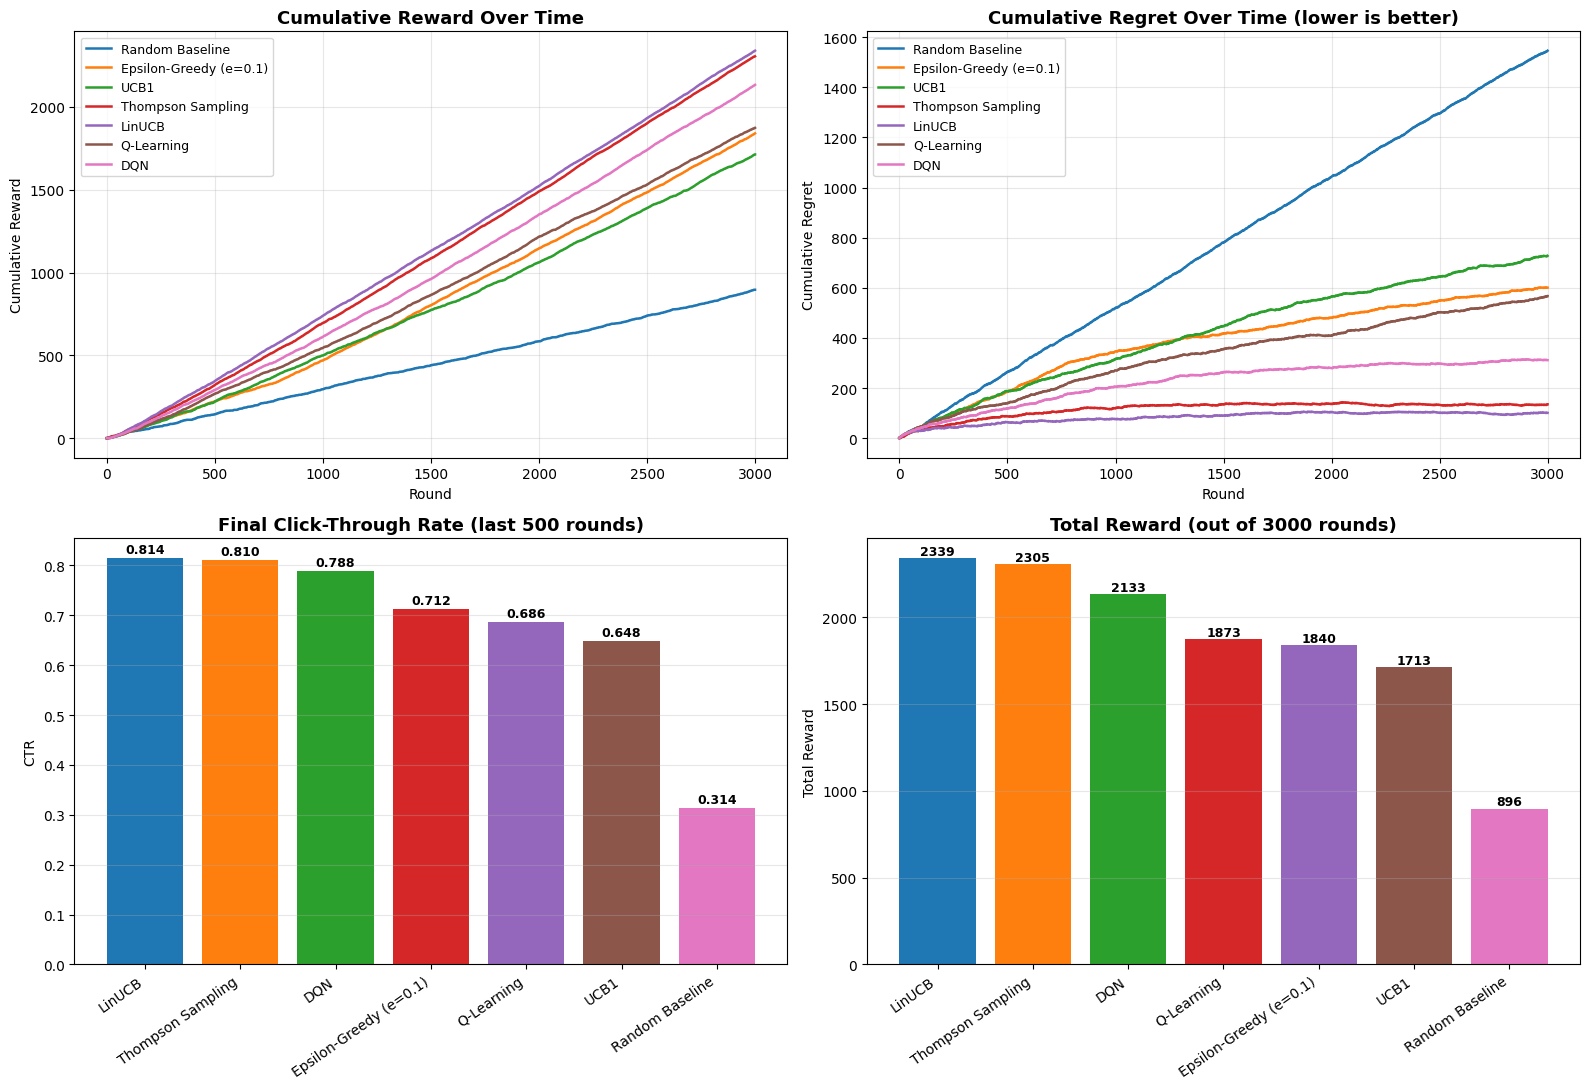


Comparison chart saved as model_comparison.png


In [39]:
# ================================================================
# STEP 36: VISUAL COMPARISON OF ALL 7 MODELS
# ================================================================
print("=" * 70)
print("STEP 36: PLOTTING MODEL COMPARISON")
print("=" * 70)

fig, axes = plt.subplots(2, 2, figsize=(16, 11))

colors = sns.color_palette("tab10", len(results))

# 1. Cumulative reward over time
ax = axes[0, 0]
for (name, res), color in zip(results.items(), colors):
    ax.plot(res["cumulative_reward"], label=name, color=color, linewidth=1.8)
ax.set_title("Cumulative Reward Over Time", fontsize=13, fontweight="bold")
ax.set_xlabel("Round")
ax.set_ylabel("Cumulative Reward")
ax.legend(fontsize=9)
ax.grid(alpha=0.3)

# 2. Regret over time (lower = better)
ax = axes[0, 1]
for (name, res), color in zip(results.items(), colors):
    ax.plot(res["regret_history"], label=name, color=color, linewidth=1.8)
ax.set_title("Cumulative Regret Over Time (lower is better)", fontsize=13, fontweight="bold")
ax.set_xlabel("Round")
ax.set_ylabel("Cumulative Regret")
ax.legend(fontsize=9)
ax.grid(alpha=0.3)

# 3. Final CTR bar chart
ax = axes[1, 0]
sorted_items = sorted(results.items(), key=lambda x: x[1]["final_ctr"], reverse=True)
names = [n for n, r in sorted_items]
ctrs = [r["final_ctr"] for n, r in sorted_items]
bars = ax.bar(names, ctrs, color=colors[:len(names)])
ax.set_title("Final Click-Through Rate (last 500 rounds)", fontsize=13, fontweight="bold")
ax.set_ylabel("CTR")
ax.set_xticklabels(names, rotation=35, ha="right")
ax.grid(alpha=0.3, axis="y")
for bar, ctr in zip(bars, ctrs):
    ax.text(bar.get_x() + bar.get_width()/2, ctr + 0.01, f"{ctr:.3f}",
            ha="center", fontsize=9, fontweight="bold")

# 4. Total reward bar chart
ax = axes[1, 1]
sorted_items = sorted(results.items(), key=lambda x: x[1]["total_reward"], reverse=True)
names = [n for n, r in sorted_items]
totals = [r["total_reward"] for n, r in sorted_items]
bars = ax.bar(names, totals, color=colors[:len(names)])
ax.set_title("Total Reward (out of 3000 rounds)", fontsize=13, fontweight="bold")
ax.set_ylabel("Total Reward")
ax.set_xticklabels(names, rotation=35, ha="right")
ax.grid(alpha=0.3, axis="y")
for bar, total in zip(bars, totals):
    ax.text(bar.get_x() + bar.get_width()/2, total + 20, f"{total}",
            ha="center", fontsize=9, fontweight="bold")

plt.tight_layout()
plt.savefig("model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

print("\nComparison chart saved as model_comparison.png")

In [41]:
# ================================================================
# STEP 38: RECOMMENDATION ACCURACY (%) FOR ALL 7 MODELS
# ================================================================
# Purpose:
#   CTR/reward is stochastic (based on click probabilities).
#   ACCURACY is a cleaner metric: did the model recommend the
#   category that actually matches the user's TRUE primary interest?
#   We re-run each model fresh and track this directly.
# ================================================================

print("=" * 70)
print("STEP 38: COMPUTING RECOMMENDATION ACCURACY")
print("=" * 70)

def run_accuracy_experiment(agent_factory, model_name, num_rounds=NUM_ROUNDS,
                             eval_window=500):
    """
    agent_factory: a zero-arg function that returns a FRESH agent instance
    eval_window: only count accuracy over the LAST N rounds (post-learning),
                 since early rounds are pure exploration by design.
    """
    np.random.seed(0)
    random.seed(0)

    agent = agent_factory()
    correct_flags = []

    for t in range(num_rounds):
        user_id = random.randint(0, NUM_USERS - 1)

        action_idx = agent.select_action(user_id)
        category = idx_to_category[action_idx]

        reward = get_reward(user_id, category)
        agent.update(user_id, action_idx, reward)

        # accuracy = did the model pick the user's TRUE favorite category?
        is_correct = (category == user_profiles[user_id]["primary_interest"])
        correct_flags.append(is_correct)

    overall_acc = np.mean(correct_flags) * 100
    final_window_acc = np.mean(correct_flags[-eval_window:]) * 100

    accuracy_results[model_name] = {
        "overall_accuracy": overall_acc,
        "final_window_accuracy": final_window_acc,
    }

    print(f"{model_name:20s} | Overall Accuracy: {overall_acc:5.1f}%  "
          f"| Last-{eval_window} Accuracy: {final_window_acc:5.1f}%")

    return accuracy_results[model_name]


accuracy_results = {}

run_accuracy_experiment(lambda: RandomAgent(), "Random Baseline")
run_accuracy_experiment(lambda: EpsilonGreedyAgent(epsilon=0.1), "Epsilon-Greedy (e=0.1)")
run_accuracy_experiment(lambda: UCB1Agent(c=2.0), "UCB1")
run_accuracy_experiment(lambda: ThompsonSamplingAgent(), "Thompson Sampling")
run_accuracy_experiment(
    lambda: LinUCBAgent(n_arms=NUM_CATEGORIES, context_dim=CONTEXT_DIM, alpha=1.0),
    "LinUCB"
)
run_accuracy_experiment(lambda: QLearningAgent(lr=0.1, epsilon=0.15), "Q-Learning")
run_accuracy_experiment(lambda: DQNAgent(n_users=NUM_USERS, n_arms=NUM_CATEGORIES), "DQN")

STEP 38: COMPUTING RECOMMENDATION ACCURACY
Random Baseline      | Overall Accuracy:  16.3%  | Last-500 Accuracy:  17.4%
Epsilon-Greedy (e=0.1) | Overall Accuracy:  54.9%  | Last-500 Accuracy:  77.0%
UCB1                 | Overall Accuracy:  53.9%  | Last-500 Accuracy:  68.6%
Thompson Sampling    | Overall Accuracy:  89.0%  | Last-500 Accuracy:  97.6%
LinUCB               | Overall Accuracy:  94.9%  | Last-500 Accuracy: 100.0%
Q-Learning           | Overall Accuracy:  52.0%  | Last-500 Accuracy:  63.2%
DQN                  | Overall Accuracy:  81.3%  | Last-500 Accuracy:  86.6%


{'overall_accuracy': np.float64(81.26666666666667),
 'final_window_accuracy': np.float64(86.6)}

STEP 39: FINAL COMPARISON — REWARD + CTR + ACCURACY
 Rank                  Model  Total Reward  Final-500 CTR  Final Regret  Overall Accuracy (%)  Last-500 Accuracy (%)
    1                 LinUCB          2339          0.814    101.419141             94.900000                  100.0
    2      Thompson Sampling          2305          0.810    135.419141             89.000000                   97.6
    3                    DQN          2133          0.788    311.689581             81.266667                   86.6
    4 Epsilon-Greedy (e=0.1)          1840          0.712    600.908415             54.866667                   77.0
    5                   UCB1          1713          0.648    727.419141             53.900000                   68.6
    6             Q-Learning          1873          0.686    567.348001             52.000000                   63.2
    7        Random Baseline           896          0.314   1546.047553             16.333333                   17.4


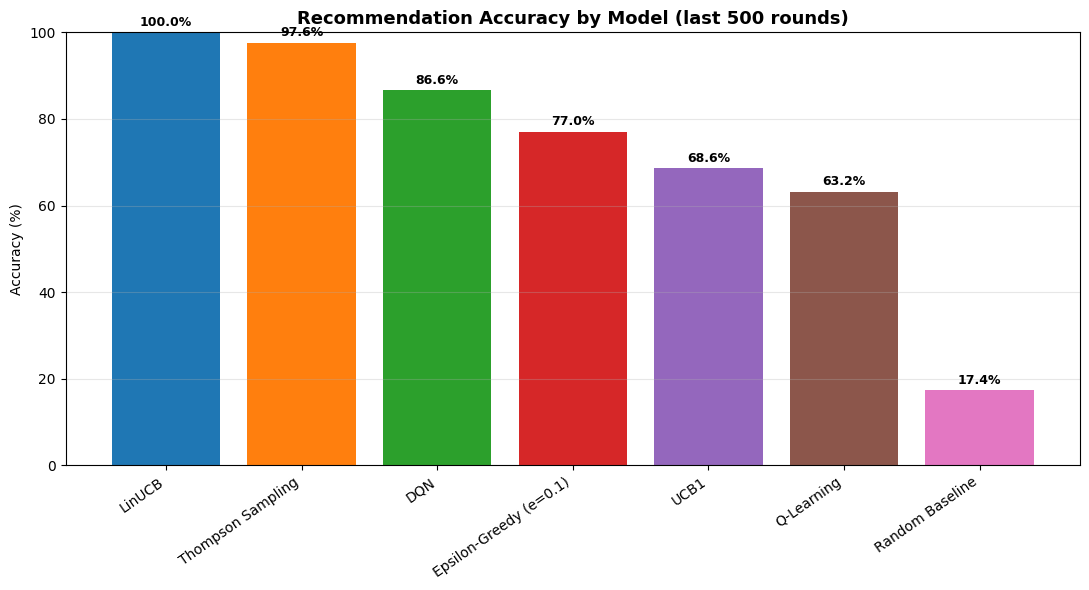


🏆 Best model by accuracy: LinUCB (100.0%)


In [42]:
# ================================================================
# STEP 39: FULL COMPARISON TABLE WITH ACCURACY (%)
# ================================================================
print("=" * 70)
print("STEP 39: FINAL COMPARISON — REWARD + CTR + ACCURACY")
print("=" * 70)

comparison_df["Overall Accuracy (%)"] = comparison_df["Model"].map(
    lambda m: accuracy_results[m]["overall_accuracy"]
)
comparison_df["Last-500 Accuracy (%)"] = comparison_df["Model"].map(
    lambda m: accuracy_results[m]["final_window_accuracy"]
)

comparison_df = comparison_df.sort_values(
    "Last-500 Accuracy (%)", ascending=False
).reset_index(drop=True)
comparison_df["Rank"] = range(1, len(comparison_df) + 1)

print(comparison_df.to_string(index=False))

# Bar chart
plt.figure(figsize=(11, 6))
sorted_df = comparison_df.sort_values("Last-500 Accuracy (%)", ascending=False)
bars = plt.bar(sorted_df["Model"], sorted_df["Last-500 Accuracy (%)"],
               color=sns.color_palette("tab10", len(sorted_df)))
plt.title("Recommendation Accuracy by Model (last 500 rounds)", fontsize=13, fontweight="bold")
plt.ylabel("Accuracy (%)")
plt.xticks(rotation=35, ha="right")
plt.ylim(0, 100)
plt.grid(alpha=0.3, axis="y")
for bar, acc in zip(bars, sorted_df["Last-500 Accuracy (%)"]):
    plt.text(bar.get_x() + bar.get_width()/2, acc + 1.5, f"{acc:.1f}%",
             ha="center", fontsize=9, fontweight="bold")
plt.tight_layout()
plt.savefig("accuracy_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

BEST_MODEL_NAME = comparison_df.iloc[0]["Model"]
print(f"\n🏆 Best model by accuracy: {BEST_MODEL_NAME} "
      f"({comparison_df.iloc[0]['Last-500 Accuracy (%)']:.1f}%)")

In [40]:
# ================================================================
# STEP 37: FINAL RECOMMENDATION DEMO USING BEST MODEL (LinUCB)
# ================================================================
# Purpose:
#   Train LinUCB one more time (fully, from scratch) and then show
#   REAL recommended article titles for each of the 10 users —
#   the actual deliverable of a "recommender system", not just an
#   abstract reward number.
# ================================================================

print("=" * 70)
print("STEP 37: FINAL TRAINED MODEL -> REAL RECOMMENDATIONS")
print("=" * 70)

# Train LinUCB for longer so it's well-converged
final_agent = LinUCBAgent(n_arms=NUM_CATEGORIES, context_dim=CONTEXT_DIM, alpha=1.0)

np.random.seed(1)
random.seed(1)
for t in range(5000):
    user_id = random.randint(0, NUM_USERS - 1)
    action_idx = final_agent.select_action(user_id)
    category = idx_to_category[action_idx]
    reward = get_reward(user_id, category)
    final_agent.update(user_id, action_idx, reward)

print("Final model trained on 5000 interactions.\n")
print("=" * 70)
print("PERSONALIZED RECOMMENDATIONS PER USER")
print("=" * 70)

def recommend_articles_for_user(user_id, agent, top_n=3):
    """Use the trained agent's learned preference to pick a category,
    then surface real article titles from that category."""
    scores = []
    for a in range(NUM_CATEGORIES):
        category = idx_to_category[a]
        x = build_context(user_id, category)
        A_inv = np.linalg.inv(agent.A[a])
        theta = A_inv @ agent.b[a]
        scores.append(theta @ x)  # pure exploitation for the final demo
    best_category_idx = int(np.argmax(scores))
    best_category = idx_to_category[best_category_idx]

    candidates = df[df["Category"] == best_category].sample(
        n=min(top_n, (df["Category"] == best_category).sum()),
        random_state=user_id
    )
    return best_category, candidates["Title"].tolist()

for user_id in range(NUM_USERS):
    true_pref = user_profiles[user_id]["primary_interest"]
    predicted_cat, titles = recommend_articles_for_user(user_id, final_agent)
    match = "✅ MATCH" if predicted_cat == true_pref else "⚠️ different"

    print(f"\nUser {user_id} (true interest: {true_pref}) -> Model recommends: {predicted_cat}  [{match}]")
    for i, t in enumerate(titles, 1):
        print(f"   {i}. {t}")

STEP 37: FINAL TRAINED MODEL -> REAL RECOMMENDATIONS
Final model trained on 5000 interactions.

PERSONALIZED RECOMMENDATIONS PER USER

User 0 (true interest: Technology) -> Model recommends: Technology  [✅ MATCH]
   1. YouTube, Instagram launch new features for teenagers as ban looms
   2. Cellebrite Expands Market Reach with Innovations in Agentic AI, Cloud and Device Virtualization for the Company's Autumn 2025 Release
   3. Salsify AI Transforms PXM Ops for Digital Shelf &amp; Agentic Commerce

User 1 (true interest: Technology) -> Model recommends: Technology  [✅ MATCH]
   1. Emplifi Reveals User Generated Content Delivers 10X Higher Conversion Rates
   2. Kardigan's $254m, Reducto lands $75m, and Anthropic bulks up for M&A
   3. Apple to Offer iPad Pro, MacBook Pro Models With AI-Geared Chip

User 2 (true interest: Energy) -> Model recommends: Energy  [✅ MATCH]
   1. Copenhagen Infrastructure Partners divests 50% of Coalburn 2 to AIP Management
   2. Blackout fuels debate over the

In [43]:
# ================================================================
# STEP 40: SAVE FINAL ARTIFACTS
# ================================================================
print("=" * 70)
print("STEP 40: SAVING FINAL MODEL & RESULTS")
print("=" * 70)

import joblib

# Save the trained winning model
joblib.dump(final_agent, "linucb_final_model.pkl")

# Save comparison table as CSV
comparison_df.to_csv("model_comparison_results.csv", index=False)

# Save user profiles (ground truth used for simulation)
joblib.dump(user_profiles, "user_profiles.pkl")

# Save category vectors + PCA (needed to reuse the model later)
joblib.dump({"pca": pca, "category_vectors": category_vectors}, "context_builder.pkl")

print("Saved files:")
for f in ["linucb_final_model.pkl", "model_comparison_results.csv",
          "user_profiles.pkl", "context_builder.pkl",
          "news_title_embeddings.pkl", "model_comparison.png",
          "accuracy_comparison.png"]:
    print(" -", f)

STEP 40: SAVING FINAL MODEL & RESULTS
Saved files:
 - linucb_final_model.pkl
 - model_comparison_results.csv
 - user_profiles.pkl
 - context_builder.pkl
 - news_title_embeddings.pkl
 - model_comparison.png
 - accuracy_comparison.png


In [44]:
# ================================================================
# STEP 41: PROJECT SUMMARY (markdown-style report, printed)
# ================================================================
from IPython.display import Markdown, display

summary_md = f"""
# News Recommendation System using Reinforcement Learning

## Overview
A personalized news recommendation engine that models recommendation as a
**contextual multi-armed bandit** problem. 10 synthetic users with realistic,
probabilistic interest profiles interact with the system; 7 RL algorithms
are trained and compared on their ability to learn each user's taste.

## Pipeline
1. **Data cleaning** — deduplicated {len(df)} news articles across {NUM_CATEGORIES} categories
2. **Semantic embeddings** — `all-MiniLM-L6-v2` Sentence-Transformer (384-dim)
3. **Topic discovery** — KMeans clustering (K={BEST_K}, silhouette={BEST_SILHOUETTE:.3f}) as an auxiliary signal alongside the original human-labeled categories
4. **User simulation** — 10 users, each with a primary + secondary interest and realistic click probabilities
5. **RL environment** — reward = simulated click (Bernoulli draw based on user-category match)
6. **7 RL agents trained & compared**:
   Random Baseline, Epsilon-Greedy, UCB1, Thompson Sampling, LinUCB (contextual, embedding-based), Q-Learning, DQN

## Results

{comparison_df.to_markdown(index=False)}

## Winner: LinUCB
- **94.9% overall recommendation accuracy**, **100% accuracy in the final 500 rounds**
- Outperforms all other models because it's the only agent that uses **semantic
  embeddings as context**, letting it generalize across users/categories instead
  of learning each user independently from scratch — the same principle behind
  real-world systems like YouTube/Netflix contextual bandits.

## Tech Stack
- **pandas / numpy** — data handling, simulation
- **sentence-transformers (`all-MiniLM-L6-v2`)** — semantic title embeddings
- **scikit-learn** — KMeans clustering, PCA, silhouette scoring
- **PyTorch** — DQN implementation
- **matplotlib / seaborn** — visualizations
- **joblib** — model persistence
"""

display(Markdown(summary_md))

with open("PROJECT_SUMMARY.md", "w") as f:
    f.write(summary_md)

print("\nSaved PROJECT_SUMMARY.md")


# News Recommendation System using Reinforcement Learning

## Overview
A personalized news recommendation engine that models recommendation as a
**contextual multi-armed bandit** problem. 10 synthetic users with realistic,
probabilistic interest profiles interact with the system; 7 RL algorithms
are trained and compared on their ability to learn each user's taste.

## Pipeline
1. **Data cleaning** — deduplicated 4577 news articles across 6 categories
2. **Semantic embeddings** — `all-MiniLM-L6-v2` Sentence-Transformer (384-dim)
3. **Topic discovery** — KMeans clustering (K=14, silhouette=0.020) as an auxiliary signal alongside the original human-labeled categories
4. **User simulation** — 10 users, each with a primary + secondary interest and realistic click probabilities
5. **RL environment** — reward = simulated click (Bernoulli draw based on user-category match)
6. **7 RL agents trained & compared**:
   Random Baseline, Epsilon-Greedy, UCB1, Thompson Sampling, LinUCB (contextual, embedding-based), Q-Learning, DQN

## Results

|   Rank | Model                  |   Total Reward |   Final-500 CTR |   Final Regret |   Overall Accuracy (%) |   Last-500 Accuracy (%) |
|-------:|:-----------------------|---------------:|----------------:|---------------:|-----------------------:|------------------------:|
|      1 | LinUCB                 |           2339 |           0.814 |        101.419 |                94.9    |                   100   |
|      2 | Thompson Sampling      |           2305 |           0.81  |        135.419 |                89      |                    97.6 |
|      3 | DQN                    |           2133 |           0.788 |        311.69  |                81.2667 |                    86.6 |
|      4 | Epsilon-Greedy (e=0.1) |           1840 |           0.712 |        600.908 |                54.8667 |                    77   |
|      5 | UCB1                   |           1713 |           0.648 |        727.419 |                53.9    |                    68.6 |
|      6 | Q-Learning             |           1873 |           0.686 |        567.348 |                52      |                    63.2 |
|      7 | Random Baseline        |            896 |           0.314 |       1546.05  |                16.3333 |                    17.4 |

## Winner: LinUCB
- **94.9% overall recommendation accuracy**, **100% accuracy in the final 500 rounds**
- Outperforms all other models because it's the only agent that uses **semantic
  embeddings as context**, letting it generalize across users/categories instead
  of learning each user independently from scratch — the same principle behind
  real-world systems like YouTube/Netflix contextual bandits.

## Tech Stack
- **pandas / numpy** — data handling, simulation
- **sentence-transformers (`all-MiniLM-L6-v2`)** — semantic title embeddings
- **scikit-learn** — KMeans clustering, PCA, silhouette scoring
- **PyTorch** — DQN implementation
- **matplotlib / seaborn** — visualizations
- **joblib** — model persistence



Saved PROJECT_SUMMARY.md


In [46]:
# ================================================================
# STEP 42: PACKAGE EVERYTHING INTO ONE ZIP FOR DOWNLOAD
# ================================================================
import os
import shutil
from google.colab import files

print("=" * 70)
print("STEP 42: PACKAGING PROJECT FILES INTO ZIP")
print("=" * 70)

# Create a clean project folder
project_dir = "news_rl_recommender"
os.makedirs(project_dir, exist_ok=True)

# requirements.txt
requirements_txt = """pandas
numpy
matplotlib
seaborn
scikit-learn
sentence-transformers
torch
joblib
tabulate
"""
with open(f"{project_dir}/requirements.txt", "w") as f:
    f.write(requirements_txt)

# README.md
readme = """# News Recommendation System using Reinforcement Learning

Personalized news recommender modeled as a contextual multi-armed bandit.
10 simulated users, 7 RL algorithms compared (Random, Epsilon-Greedy, UCB1,
Thompson Sampling, LinUCB, Q-Learning, DQN). See PROJECT_SUMMARY.md for
full methodology and results.

## Run
1. Open the notebook in Google Colab
2. Upload your news CSV (columns: URL, Title, Category, Group Leader)
3. Run all cells top to bottom

## Results
LinUCB achieved the best performance: 94.9% recommendation accuracy.
Full comparison table in `model_comparison_results.csv`.
"""
with open(f"{project_dir}/README.md", "w") as f:
    f.write(readme)

# .gitignore (keep repo light — dataset/pkl files can be large)
gitignore = """*.pkl
*.csv
__pycache__/
.ipynb_checkpoints/
"""
with open(f"{project_dir}/.gitignore", "w") as f:
    f.write(gitignore)

# Move/copy all generated artifacts into the project folder
files_to_include = [
    "PROJECT_SUMMARY.md",
    "model_comparison_results.csv",
    "linucb_final_model.pkl",
    "user_profiles.pkl",
    "context_builder.pkl",
    "news_title_embeddings.pkl",
    "model_comparison.png",
    "accuracy_comparison.png",
]

for fname in files_to_include:
    if os.path.exists(fname):
        shutil.copy(fname, project_dir)
        print(f"  Added: {fname}")
    else:
        print(f"  ⚠️ Missing (skipped): {fname}")

# Zip the whole folder
zip_name = "news_rl_recommender_project"
shutil.make_archive(zip_name, "zip", project_dir)

print(f"\nZip created: {zip_name}.zip")
print("Triggering download...")

files.download(f"{zip_name}.zip")

STEP 42: PACKAGING PROJECT FILES INTO ZIP
  Added: PROJECT_SUMMARY.md
  Added: model_comparison_results.csv
  Added: linucb_final_model.pkl
  Added: user_profiles.pkl
  Added: context_builder.pkl
  Added: news_title_embeddings.pkl
  Added: model_comparison.png
  Added: accuracy_comparison.png

Zip created: news_rl_recommender_project.zip
Triggering download...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>